### Use multiplet statistics through the ACM pipeline

In [1]:
import matplotlib.pyplot as plt
import numpy as np

%matplotlib inline
%config InlineBackend.figure_format = "retina"

from helpers import load_estimator_parameters, make_lagrangian_mock

from acm import setup_logging
from acm.estimators.galaxy_clustering.multiplets import GalaxyMultiplets

setup_logging()

/global/common/software/desi/users/adematti/perlmutter/cosmodesiconda/20260321-1.0.0/code/mockfactory/main/lib/python3.12/site-packages/mockfactory/lagrangian_mock.py:1: FutureWarning: The pmesh-based mocks of mockfactory (EulerianLinearMock, LagrangianLinearMock) are deprecated and will be removed; use the jaxpower routines instead, in jaxpower.mock (generate_gaussian_mesh, generate_spectrum2_mesh, generate_uniform_particles).
  from .gaussian_mock import BaseGaussianMock, _get_los


In [2]:
# mock is centered on 0; multiplets needs [0, L); multiplet class handles this correctly now
data_positions, boxsize = make_lagrangian_mock(boxsize=500.0, los="z")

/global/common/software/desi/users/adematti/perlmutter/cosmodesiconda/20260321-1.0.0/code/cosmoprimo/main/lib/python3.12/site-packages/cosmoprimo/eisenstein_hu.py:25: UserWarning: EisensteinHuEngine cannot cope with massive neutrinos
  warnings.warn(


[000003.59]  11-06 11:14  LagrangianLinearMock:177 INFO White noise generated.
[000009.67]  11-06 11:14  LagrangianLinearMock:177 INFO Poisson sampling done, total number of objects is 100301.
[000012.03]  11-06 11:14  LagrangianLinearMock:177 INFO Catalog produced. Assigning in cell shift.


In [3]:
print(boxsize)
print(np.max(data_positions[:,0]), np.min(data_positions[:,0]))
print(np.max(data_positions[:,2]), np.min(data_positions[:,2]))

500.0
249.99904310778498 -249.99919424342227
257.82294549533015 -260.68540472191586


In [4]:
mult = GalaxyMultiplets(r_max=7.0, r_perp_max=1.05, los="z", nthreads=4)
res = mult.identify_multiplets(data_positions, boxsize)
edges = (np.linspace(2.0, 30.0, 14), np.linspace(-60, 60, 121))
corr = mult.compute_all_cross_correlations(positions=data_positions, boxsize=boxsize, edges=edges, pimax=None)

[000012.35]  11-06 11:14  acm.estimators.galaxy_clustering.multiplets:80 INFO Initializing GalaxyMultiplets.
[000012.35]  11-06 11:14  acm.estimators.galaxy_clustering.multiplets:376 INFO Starting multiplet identification
[000012.35]  11-06 11:14  acm.estimators.galaxy_clustering.multiplets:125 INFO Finding pairs with r_max=7.0, r_perp_max=1.05
[000012.50]  11-06 11:14  acm.estimators.galaxy_clustering.multiplets:143 INFO Found 292251 pairs within r_max=7.0
[000012.59]  11-06 11:14  acm.estimators.galaxy_clustering.multiplets:193 INFO Found 33553 pairs satisfying all criteria
[000012.59]  11-06 11:14  acm.estimators.galaxy_clustering.multiplets:194 INFO   Non-boundary: 33389, Boundary: 164
[000012.62]  11-06 11:14  acm.estimators.galaxy_clustering.multiplets:395 INFO Found 66227 singlets (66.03%)
[000012.62]  11-06 11:14  acm.estimators.galaxy_clustering.multiplets:398 INFO 33.97% of galaxies are in multiplets
[000012.62]  11-06 11:14  acm.estimators.galaxy_clustering.multiplets:246 IN

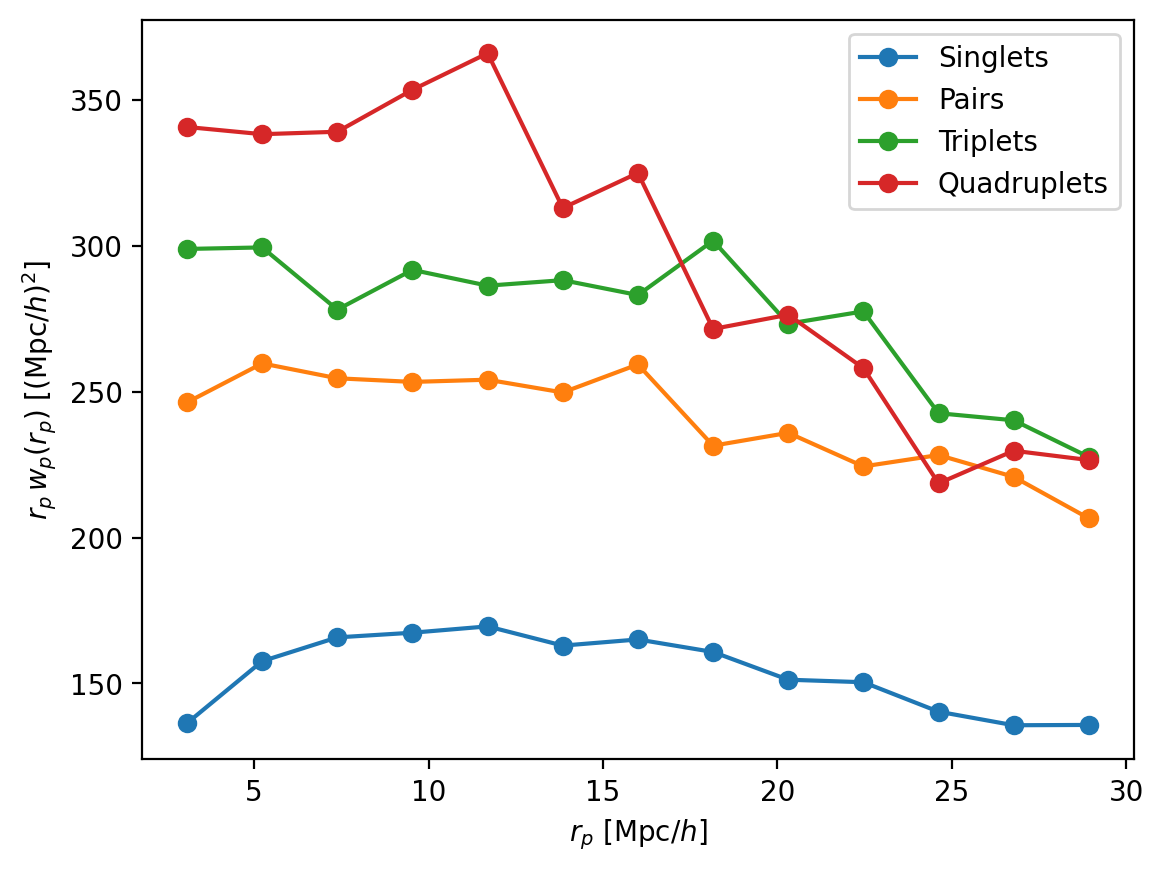

In [5]:
rp_edges = edges[0]
rp = 0.5 * (rp_edges[:-1] + rp_edges[1:])

for key, label in [("singlet", "Singlets"), ("pair", "Pairs"),
                   ("triplet", "Triplets"), ("quadruplet", "Quadruplets")]:
    if key in corr:
        plt.plot(rp, rp * np.asarray(corr[key]), marker="o", label=label)

plt.xlabel(r"$r_p$ [Mpc/$h$]")
plt.ylabel(r"$r_p\, w_p(r_p)$ [(Mpc/$h$)$^2$]")
plt.legend()

#### For cutsky geometry
- Pass `boxsize=None` to use the cutsky mode.
- Galaxy and random positions take the rdd form: `[RA, DEC, distance]`
- `compute_all_cross_correlations` requires `randoms_positions`; `data_weights` and
  `randoms_weights` are optional. The Davis-Peebles estimator is used.
- Returned singlet and multiplet coordinates are also `[RA, DEC, distance]`.

If boxsize is None and the input positions are not `[RA, DEC, distance]` (e.g. Cartesian), the class reports an error.

In [6]:
mult = GalaxyMultiplets(r_max=7.0, r_perp_max=1.05, los="z", nthreads=4)
res_test = mult.identify_multiplets(data_positions, boxsize=None)

[000013.69]  11-06 11:14  acm.estimators.galaxy_clustering.multiplets:80 INFO Initializing GalaxyMultiplets.
[000013.69]  11-06 11:14  acm.estimators.galaxy_clustering.multiplets:376 INFO Starting multiplet identification


ValueError: positions must be [RA, DEC, distance] with RA in [0, 360], DEC in [-90, 90] (degrees) and distance > 0 in cutsky mode (boxsize=None). Got Cartesian positions?